# 06 — Measuring age and metallicity: fitting one SSP with FaSTAR

*Lecture 1: stellar populations*

We make a **mock galaxy spectrum** with known age and metallicity, add the effects from notebook 05 (velocity dispersion, noise), and try to get the parameters back by comparing it with FaSTAR models:

$$\chi^2(t, Z) = \sum_\mathrm{pixels} \left(\frac{F_\mathrm{obs} - A\,F_\mathrm{model}(t, Z)}{\sigma_\mathrm{noise}}\right)^2 .$$

The amplitude $A$ (the galaxy's mass and distance) is solved for exactly at each step (it is linear). You will meet the **age–metallicity degeneracy** of the lecture in numbers — and see why spectra beat colours.

Tools: FaSTAR, numpy, scipy (`scipy.optimize.minimize`). A model takes ~0.2 s; the whole notebook runs in ~5 minutes.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Azeret/stellar-populations-lectures/blob/main/notebooks/06_fitting_an_SSP_with_FaSTAR.ipynb)  ← run this notebook in your browser, nothing to install

In [1]:
# Running in Google Colab? This cell fetches the course code and installs fastar-astro.
# On your own computer it does nothing.
import sys, os, subprocess
if 'google.colab' in sys.modules:
    if not os.path.isdir('/content/stellar-populations-lectures'):
        subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/Azeret/stellar-populations-lectures.git',
                        '/content/stellar-populations-lectures'], check=True)
    os.chdir('/content/stellar-populations-lectures/notebooks')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'fastar-astro'], check=True)

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # makes the small 'stellarpops' package importable
import numpy as np
import matplotlib.pyplot as plt
from stellarpops.style import use_slide_style
use_slide_style(dark=False, scale=0.7)       # dark=True gives the lecture-slide look

from scipy.optimize import minimize
from fastar import IntegratedSSPSynthesizer, imf
from stellarpops.spectra import log_rebin, broaden_velocity, add_noise

ssp = IntegratedSSPSynthesizer(imf_function=imf.kroupa)
wave = np.array(ssp.wave)
ln_lam, _, velscale = log_rebin(wave, np.ones_like(wave))
lam = np.exp(ln_lam)
FIT = (lam > 3800) & (lam < 7200)          # pixels used in the fit

_cache = {}
def model(age, met, sigma):
    # FaSTAR SSP, log-rebinned and broadened to the galaxy's velocity dispersion (cached)
    key = (round(float(age), 5), round(float(met), 5), sigma)
    if key not in _cache:
        s = np.array(ssp.synthesize(age=float(age), met=float(met)))
        s = np.interp(ln_lam, np.log(wave), s)
        _cache[key] = broaden_velocity(s / np.median(s), velscale, sigma)
    return _cache[key]

## 1. A mock galaxy

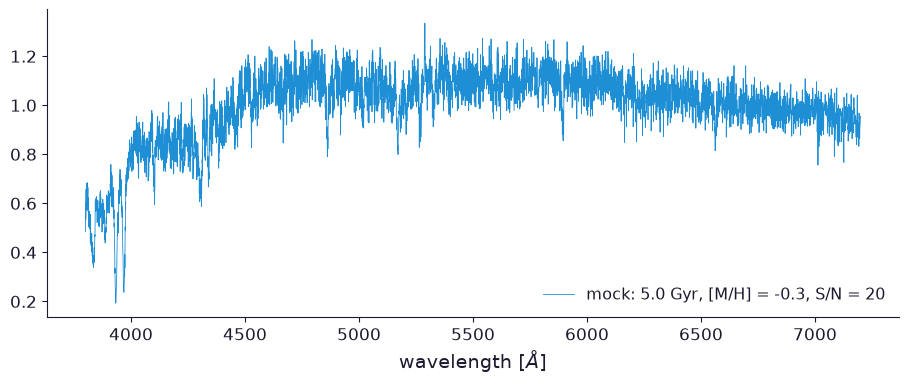

In [3]:
TRUE = dict(age=5.0, met=-0.3)
SIGMA = 150.0          # km/s, assumed known (pPXF measures it, notebook 07)
SNR = 20               # per pixel

clean = model(TRUE['age'], TRUE['met'], SIGMA)
obs, err = add_noise(clean, SNR, rng=42)

plt.figure(figsize=(11, 4))
plt.plot(lam[FIT], obs[FIT], lw=0.6, label=f'mock: {TRUE["age"]} Gyr, [M/H] = {TRUE["met"]}, S/N = {SNR}')
plt.xlabel(r'wavelength [$\AA$]'); plt.legend()

## 2. χ² with the best amplitude

For fixed $(t, Z)$ the best amplitude is $A = \sum (F_\mathrm{obs} F_\mathrm{mod}/\sigma^2) / \sum (F_\mathrm{mod}^2/\sigma^2)$ — a one-line linear fit.

In [4]:
def chi2(age, met, data=obs, noise=err, sigma=SIGMA, mask=FIT):
    m = model(age, met, sigma)[mask]
    d, e = data[mask], noise[mask]
    A = np.sum(d * m / e**2) / np.sum(m**2 / e**2)
    return np.sum(((d - A * m) / e) ** 2)

print('chi2 at the truth:', round(chi2(**TRUE)), 'for', FIT.sum(), 'pixels  (expect about the number of pixels)')
print('chi2 at 10 Gyr, solar:', round(chi2(10.0, 0.0)))

chi2 at the truth: 5309 for 5261 pixels  (expect about the number of pixels)
chi2 at 10 Gyr, solar: 40528


## 3. The χ² landscape: a diagonal valley

We evaluate χ² on a grid. The colours show how much worse than the best model each point is (log scale).

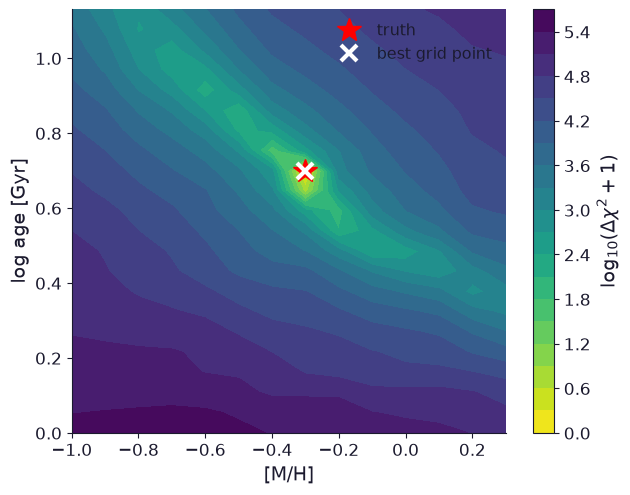

In [5]:
ages = np.geomspace(1.0, 13.5, 22)
mets = np.linspace(-1.0, 0.3, 14)
chi = np.array([[chi2(a, m) for m in mets] for a in ages])

fig, ax = plt.subplots(figsize=(7, 5.5))
cs = ax.contourf(mets, np.log10(ages), np.log10(chi - chi.min() + 1), levels=20, cmap='viridis_r')
plt.colorbar(cs, label=r'log$_{10}(\Delta\chi^2 + 1)$')
ax.plot(TRUE['met'], np.log10(TRUE['age']), 'r*', ms=18, label='truth')
i, j = np.unravel_index(chi.argmin(), chi.shape)
ax.plot(mets[j], np.log10(ages[i]), 'wx', ms=12, mew=3, label='best grid point')
ax.set_xlabel('[M/H]'); ax.set_ylabel('log age [Gyr]'); ax.legend()

**Question.** Which way does the valley of good fits run? Relate it to the "older or more metal-rich?" slide: older *and* more metal-poor (or younger and more metal-rich) look alike.

## 4. A proper minimisation and the uncertainty

Starting from the best grid point, `scipy.optimize.minimize` (Nelder–Mead, no derivatives) finds the minimum in $(\log t, [M/H])$.
Then we map $\Delta\chi^2$ on a fine grid around it: $\Delta\chi^2 = 2.3$ and $6.2$ enclose the 68% and 95% regions for two parameters.

best fit: age = 5.05 Gyr, [M/H] = -0.300   (truth 5.0 Gyr, -0.3),  31 models


Text(0.5, 1.0, '$\\Delta\\chi^2$ = 2.3, 6.2, 11.8')

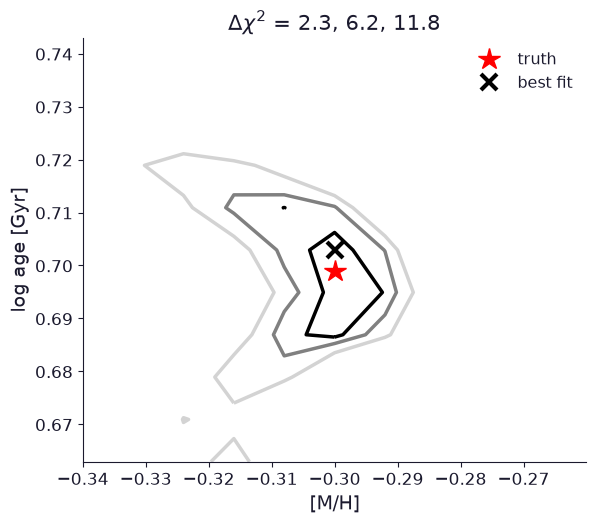

In [6]:
def f(p):
    la, met = p
    if not (np.log10(0.05) < la < np.log10(13.9) and -2.4 < met < 0.29):
        return 1e30
    return chi2(10 ** la, met)

res = minimize(f, x0=[np.log10(ages[i]), mets[j]], method='Nelder-Mead', options=dict(xatol=1e-3, fatol=0.5))
la0, m0 = res.x
print(f'best fit: age = {10 ** la0:.2f} Gyr, [M/H] = {m0:+.3f}   (truth {TRUE["age"]} Gyr, {TRUE["met"]}),  {res.nfev} models')

dla, dm = np.linspace(-0.04, 0.04, 11), np.linspace(-0.04, 0.04, 11)
fine = np.array([[f([la0 + a, m0 + b]) for b in dm] for a in dla])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.contour(m0 + dm, la0 + dla, fine - fine.min(), levels=[2.3, 6.2, 11.8], colors=['k', 'grey', 'lightgrey'])
ax.plot(TRUE['met'], np.log10(TRUE['age']), 'r*', ms=16, label='truth')
ax.plot(m0, la0, 'kx', ms=12, mew=3, label='best fit')
ax.set_xlabel('[M/H]'); ax.set_ylabel('log age [Gyr]'); ax.legend(); ax.set_title(r'$\Delta\chi^2$ = 2.3, 6.2, 11.8')

The ellipse is **tilted** — that is the degeneracy — but tiny: a full spectrum with perfect models pins down age and metallicity to a few per cent. In real life the error budget is dominated by the *models* (stellar libraries, isochrones, the IMF, α-enhancement), not by the noise.

## 5. Repeat with new noise

Fit 5 noise realisations at three S/N values (a few minutes). The scatter of the results is the real statistical uncertainty.

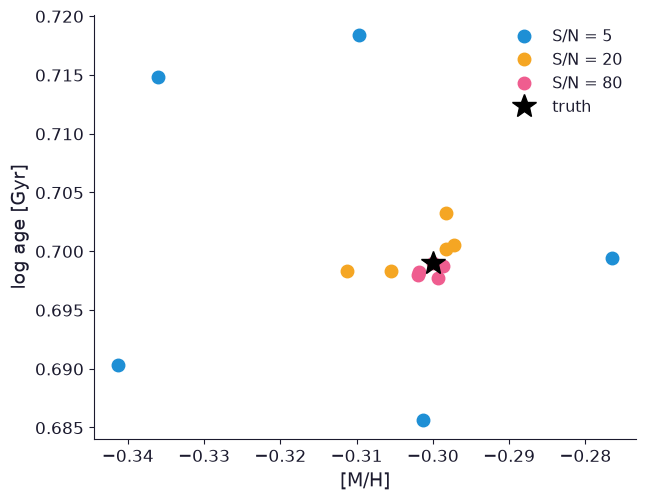

In [7]:
results = {}
for snr in [5, 20, 80]:
    out = []
    for seed in range(5):
        d, e = add_noise(clean, snr, rng=100 + seed)
        g = lambda p: 1e30 if not (-1.3 < p[0] < 1.14 and -2.4 < p[1] < 0.29) else chi2(10 ** p[0], p[1], data=d, noise=e)
        out.append(minimize(g, x0=[np.log10(TRUE['age']), TRUE['met']], method='Nelder-Mead',
                            options=dict(xatol=2e-3, fatol=0.5)).x)
    results[snr] = np.array(out)

fig, ax = plt.subplots(figsize=(7, 5.5))
for snr, r in results.items():
    ax.plot(r[:, 1], r[:, 0], 'o', ms=9, label=f'S/N = {snr}')
ax.plot(TRUE['met'], np.log10(TRUE['age']), 'k*', ms=18, label='truth')
ax.set_xlabel('[M/H]'); ax.set_ylabel('log age [Gyr]'); ax.legend()

## 6. Colours only

Now throw the lines away: measure the mean flux in six broad bands (like photometry) with 2% errors, and fit those. Compare the allowed region with the full-spectrum one.

Text(0.5, 1.0, 'orange: six colours (2% errors), black: full spectrum')

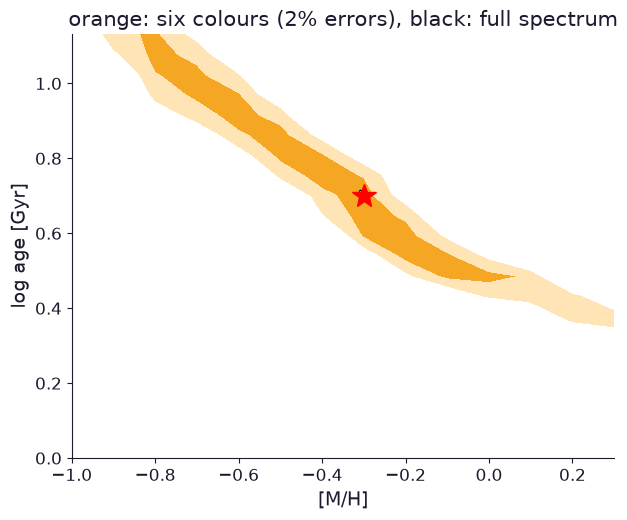

In [8]:
BANDS = [(3800, 4300), (4300, 4800), (4800, 5300), (5300, 5800), (5800, 6400), (6400, 7200)]
def bandflux(s):
    f = np.array([s[(lam > lo) & (lam < hi)].mean() for lo, hi in BANDS])
    return f / f[3]                              # normalise: only the shape (colours) matters

phot = bandflux(clean)
ephot = 0.02 * phot
def chi2_phot(age, met):
    return np.sum(((phot - bandflux(model(age, met, SIGMA))) / ephot) ** 2)

chi_p = np.array([[chi2_phot(a, m) for m in mets] for a in ages])     # reuses the cached models
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.contourf(mets, np.log10(ages), chi_p - chi_p.min(), levels=[0, 2.3, 6.2], colors=['C1', 'moccasin'])
ax.contour(m0 + dm, la0 + dla, fine - fine.min(), levels=[2.3], colors='k')
ax.plot(TRUE['met'], np.log10(TRUE['age']), 'r*', ms=18)
ax.set_xlabel('[M/H]'); ax.set_ylabel('log age [Gyr]')
ax.set_title('orange: six colours (2% errors), black: full spectrum')

**This is the degeneracy of the lecture:** with colours alone, a whole diagonal band of (age, metallicity) is allowed. Absorption lines (Hβ for age, Mg b and Fe for metals) break it.

## Exercises

1. Fit with the wrong velocity dispersion (e.g. `sigma=100` in `chi2`). Which parameter is biased, and why?
2. Make the mock with a bottom-heavy IMF: `IntegratedSSPSynthesizer(imf_function=imf.single_power_law)` with `imf_params={'alpha': 3.0}`, and fit it with Kroupa models. Is the fit bad? Are age and metallicity biased?
3. Mask everything except Hβ, Mg b and Fe5270/5335 (`mask=` argument of `chi2`). How much precision do you lose?
4. Add dust to the mock (multiply by $(\lambda/5500\,\AA)^{0.3}$) and fit the colours again. Which way does the answer move?
5. Real galaxies are not one SSP — that is notebook 07.